### Project 1           Question 1

In [7]:
# =====================================================
# BANK MARKETING: TERM DEPOSIT SUBSCRIPTION PREDICTION
# =====================================================

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from sklearn.inspection import permutation_importance


# 2. LOADING THE DATASET

df = pd.read_csv("bank-additional-full.csv", sep=";")

print("Original dataset shape:", df.shape)
print(df.head())

print("\nDataset information:")
df.info()


# 3. DATA EXPLORATION

print("\nDescriptive statistics:")
print(df.describe(include="all").T)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

print("\nTarget distribution:")
print(df["y"].value_counts())

print("\nTarget percentages:")
print(df["y"].value_counts(normalize=True) * 100)


Original dataset shape: (41188, 21)
   age        job  marital    education  default housing loan    contact  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   
1   57   services  married  high.school  unknown      no   no  telephone   
2   37   services  married  high.school       no     yes   no  telephone   
3   40     admin.  married     basic.6y       no      no   no  telephone   
4   56   services  married  high.school       no      no  yes  telephone   

  month day_of_week  ...  campaign  pdays  previous     poutcome emp.var.rate  \
0   may         mon  ...         1    999         0  nonexistent          1.1   
1   may         mon  ...         1    999         0  nonexistent          1.1   
2   may         mon  ...         1    999         0  nonexistent          1.1   
3   may         mon  ...         1    999         0  nonexistent          1.1   
4   may         mon  ...         1    999         0  nonexistent          1.1   

   cons.price.idx  c

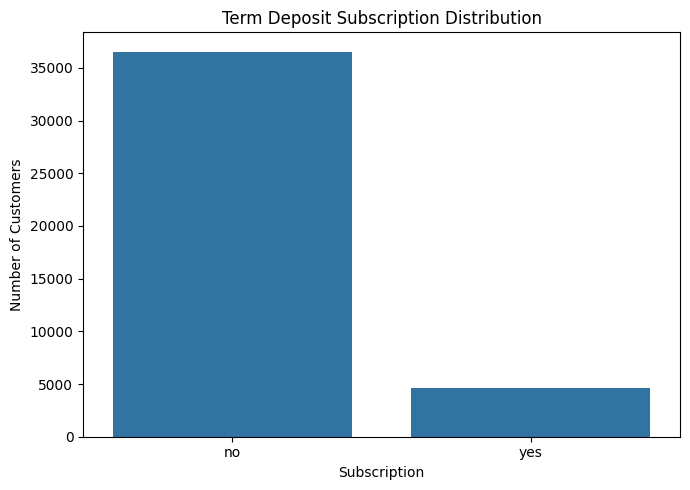

In [8]:
# 4. VISUALISE TARGET DISTRIBUTION

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="y")

plt.title("Term Deposit Subscription Distribution")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


In [9]:
# 5. REMOVE EXACT DUPLICATES

df = df.drop_duplicates().copy()

print("\nShape after removing duplicates:", df.shape)



Shape after removing duplicates: (41176, 21)


In [12]:
# PREPARE FEATURES AND TARGET VARIAABLES

# Exclude duration to prevent data leakage.
# It is only available after the telephone call.

X = df.drop(columns=["y", "duration"])

y = df["y"].map({
    "no": 0,
    "yes": 1
})

# Identify numerical and categorical columns

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

#  TRAINING THE-TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))



Training records: 32940
Testing records: 8236


In [16]:
#  DATA PREPROCESSING

# Numerical preprocessing

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)
#  MAJORITY-CLASS BASELINE

baseline = DummyClassifier(
    strategy="most_frequent"
)

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

print("\nMAJORITY-CLASS BASELINE")

print("Accuracy:",
      accuracy_score(y_test, baseline_pred))

print("Precision:",
      precision_score(y_test, baseline_pred, zero_division=0))

print("Recall:",
      recall_score(y_test, baseline_pred, zero_division=0))

print("F1-score:",
      f1_score(y_test, baseline_pred, zero_division=0))


MAJORITY-CLASS BASELINE
Accuracy: 0.8873239436619719
Precision: 0.0
Recall: 0.0
F1-score: 0.0


In [17]:

# 


 Logistic Regression
---------------------------------------------
Accuracy: 0.8303
Precision: 0.3591
Recall: 0.6455
F1-score: 0.4615
ROC-AUC: 0.8002
PR-AUC: 0.4466

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.85      0.90      7308
           1       0.36      0.65      0.46       928

    accuracy                           0.83      8236
   macro avg       0.65      0.75      0.68      8236
weighted avg       0.88      0.83      0.85      8236



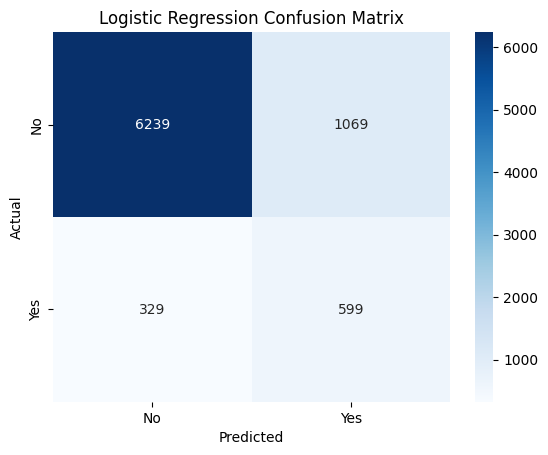


 Random Forest
---------------------------------------------
Accuracy: 0.8878
Precision: 0.5022
Recall: 0.4957
F1-score: 0.4989
ROC-AUC: 0.7985
PR-AUC: 0.4685

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.94      0.94      7308
           1       0.50      0.50      0.50       928

    accuracy                           0.89      8236
   macro avg       0.72      0.72      0.72      8236
weighted avg       0.89      0.89      0.89      8236



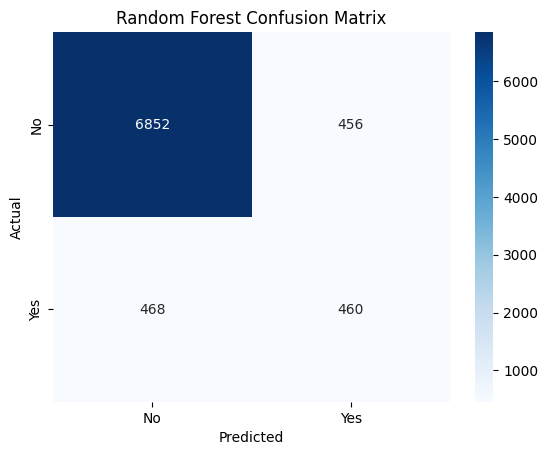

In [20]:
# LOGISTIC REGRESSION

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        solver="liblinear"
    ))
])

logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_test)

logistic_prob = logistic_model.predict_proba(X_test)[:, 1]

#  RANDOM FOREST

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=250,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_prob = rf_model.predict_proba(X_test)[:, 1]

#  MODEL EVALUATION FUNCTION

def evaluate_model(name, actual, predicted, probabilities):

    print("\n", name)
    print("-" * 45)

    print("Accuracy:",
          round(accuracy_score(actual, predicted), 4))

    print("Precision:",
          round(precision_score(actual, predicted), 4))

    print("Recall:",
          round(recall_score(actual, predicted), 4))

    print("F1-score:",
          round(f1_score(actual, predicted), 4))

    print("ROC-AUC:",
          round(roc_auc_score(actual, probabilities), 4))

    print("PR-AUC:",
          round(average_precision_score(actual, probabilities), 4))

    print("\nClassification Report:")
    print(classification_report(actual, predicted))

    cm = confusion_matrix(actual, predicted)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No", "Yes"],
        yticklabels=["No", "Yes"]
    )

    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()
    #  EVALUATING  BOTH MODELS

evaluate_model(
    "Logistic Regression",
    y_test,
    logistic_pred,
    logistic_prob
)

evaluate_model(
    "Random Forest",
    y_test,
    rf_pred,
    rf_prob
)

In [21]:

#  COMPARE MODELS

comparison = pd.DataFrame({
    "Model": [
        "Majority Baseline",
        "Logistic Regression",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test, baseline_pred),
        accuracy_score(y_test, logistic_pred),
        accuracy_score(y_test, rf_pred)
    ],

    "Precision": [
        precision_score(y_test, baseline_pred, zero_division=0),
        precision_score(y_test, logistic_pred),
        precision_score(y_test, rf_pred)
    ],

    "Recall": [
        recall_score(y_test, baseline_pred, zero_division=0),
        recall_score(y_test, logistic_pred),
        recall_score(y_test, rf_pred)
    ],

    "F1-score": [
        f1_score(y_test, baseline_pred, zero_division=0),
        f1_score(y_test, logistic_pred),
        f1_score(y_test, rf_pred)
    ],

    "ROC-AUC": [
        0.5,
        roc_auc_score(y_test, logistic_prob),
        roc_auc_score(y_test, rf_prob)
    ]
})

print("\nMODEL COMPARISON")
print(comparison.round(4))

comparison.to_csv(
    "Bank_Marketing_Model_Comparison.csv",
    index=False
)




MODEL COMPARISON
                 Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
0    Majority Baseline    0.8873     0.0000  0.0000    0.0000   0.5000
1  Logistic Regression    0.8303     0.3591  0.6455    0.4615   0.8002
2        Random Forest    0.8878     0.5022  0.4957    0.4989   0.7985



FEATURE IMPORTANCE
          Feature  Importance
17      euribor3m    0.065471
14   emp.var.rate    0.039779
7         contact    0.039007
18    nr.employed    0.036836
8           month    0.011061
11          pdays    0.007514
10       campaign    0.007232
3       education    0.006780
4         default    0.006752
2         marital    0.005980
6            loan    0.003515
9     day_of_week    0.002903
0             age   -0.000340
5         housing   -0.001274
16  cons.conf.idx   -0.001920


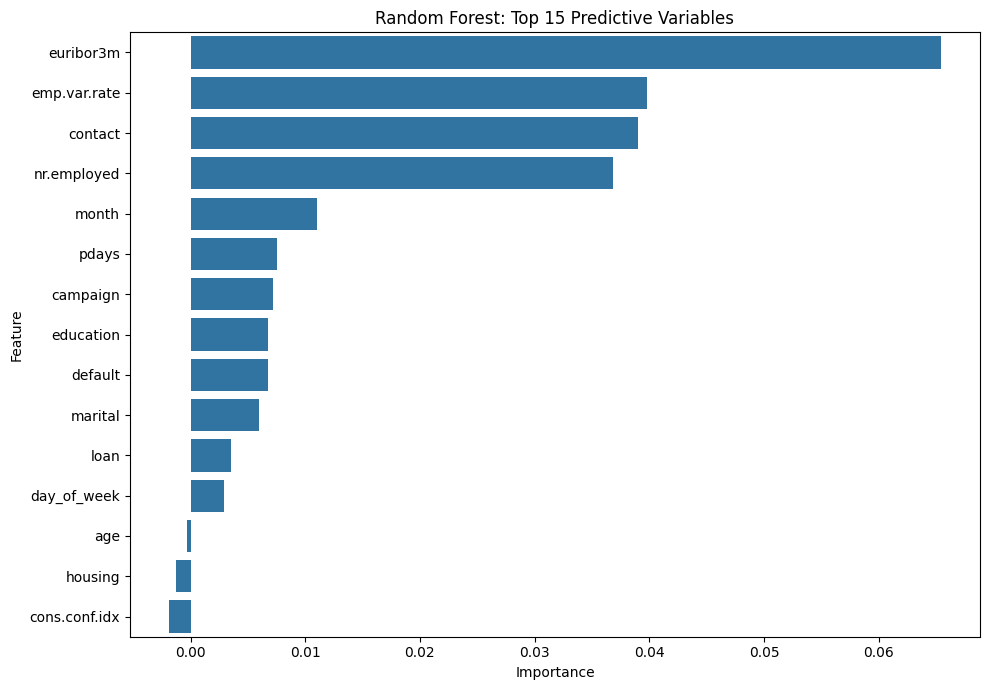

In [22]:
#  RANDOM FOREST FEATURE IMPORTANCE
# Permutation importance uses the original input variables.

importance = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=3,
    random_state=42,
    scoring="f1",
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nFEATURE IMPORTANCE")
print(feature_importance.head(15))

# Visualisation

plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Random Forest: Top 15 Predictive Variables")
plt.tight_layout()
plt.show()

feature_importance.to_csv(
    "Bank_Marketing_Feature_Importance.csv",
    index=False
)


In [26]:
# EXPERIMENT WITH A DIFFERENT CLASSIFICATION THRESHOLD

# Random Forest default threshold is 0.5.
# Lowering it can identify more potential subscribers.

threshold = 0.40

rf_threshold_pred = (
    rf_prob >= threshold
).astype(int)

print("\nRANDOM FOREST AT THRESHOLD 0.40")

print("Accuracy:",
      accuracy_score(y_test, rf_threshold_pred))

print("Precision:",
      precision_score(y_test, rf_threshold_pred))

print("Recall:",
      recall_score(y_test, rf_threshold_pred))

print("F1-score:",
      f1_score(y_test, rf_threshold_pred))
      #  SAVE THE CLEANED DATASET

df.to_csv(
    "Bank_Marketing_Cleaned.csv",
    index=False
)
print("\nAnalysis completed successfully.")


RANDOM FOREST AT THRESHOLD 0.40
Accuracy: 0.8676542010684798
Precision: 0.4352
Recall: 0.5862068965517241
F1-score: 0.4995408631772268

Analysis completed successfully.


Question2

In [33]:
from sklearn.inspection import permutation_importance
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

#  LOAD THE DATASET
df = pd.read_csv("bank-additional-full.csv", sep=";")

print("Dataset successfully loaded.")
print("Dataset dimensions:", df.shape)

display(df.head())

#  UNDERSTANDING THE DATASET
print("Dataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe(include="all").T)

print("\nVariable data types:")
display(df.dtypes.to_frame("Data Type"))

print("\nNumber of observations:", df.shape[0])
print("Number of variables:", df.shape[1])


#  IDENTIFY MISSING VALUES
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing)

print("Total missing values:", df.isnull().sum().sum())


#  IDENTIFY UNKNOWN VALUES
# 'unknown' is a recorded category, not necessarily a missing value.

unknown_counts = {}

for col in df.select_dtypes(include="object").columns:
    unknown_counts[col] = (df[col] == "unknown").sum()

unknown_table = pd.DataFrame.from_dict(
    unknown_counts, orient="index", columns=["Unknown Count"]
)

display(unknown_table)


#  CHECK DUPLICATES
duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

df = df.drop_duplicates().copy()

print("Dataset shape after removing duplicates:", df.shape)


Dataset successfully loaded.
Dataset dimensions: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,41188.0,NaN,NaN,NaN,40.02406,10.42125,17.0,32.0,38.0,47.0,98.0
job,41188,12,admin.,10422,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,41188,4,married,24928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,41188,8,university.degree,12168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,41188,3,no,32588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,41188,3,yes,21576,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,41188,3,no,33950,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,41188,2,cellular,26144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,41188,10,may,13769,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,41188,5,thu,8623,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Variable data types:


,Data Type
age,int64
job,object
marital,object
education,object
default,object
housing,object
loan,object
contact,object
month,object
day_of_week,object



Number of observations: 41188
Number of variables: 21


,Missing Values,Missing Percentage
age,0,0.0
job,0,0.0
marital,0,0.0
education,0,0.0
default,0,0.0
housing,0,0.0
loan,0,0.0
contact,0,0.0
month,0,0.0
day_of_week,0,0.0


Total missing values: 0


,Unknown Count
job,330
marital,80
education,1731
default,8597
housing,990
loan,990
contact,0
month,0
day_of_week,0
poutcome,0


Number of duplicate records: 12
Dataset shape after removing duplicates: (41176, 21)


Target variable distribution:


y
no     36537
yes     4639
Name: count, dtype: int64


Target percentage:


y
no     88.73
yes    11.27
Name: proportion, dtype: float64

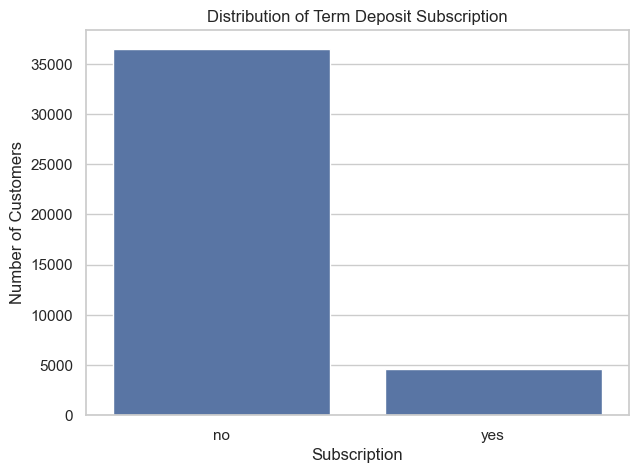

,count,mean,std,min,25%,50%,75%,max
age,41176.0,40.023800,10.420680,17.000,32.000,38.000,47.000,98.000
duration,41176.0,258.315815,259.305321,0.000,102.000,180.000,319.000,4918.000
campaign,41176.0,2.567879,2.770318,1.000,1.000,2.000,3.000,56.000
pdays,41176.0,962.464810,186.937102,0.000,999.000,999.000,999.000,999.000
previous,41176.0,0.173013,0.494964,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41176.0,0.081922,1.570883,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41176.0,93.575720,0.578839,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41176.0,-40.502863,4.627860,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41176.0,3.621293,1.734437,0.634,1.344,4.857,4.961,5.045
nr.employed,41176.0,5167.034870,72.251364,4963.600,5099.100,5191.000,5228.100,5228.100


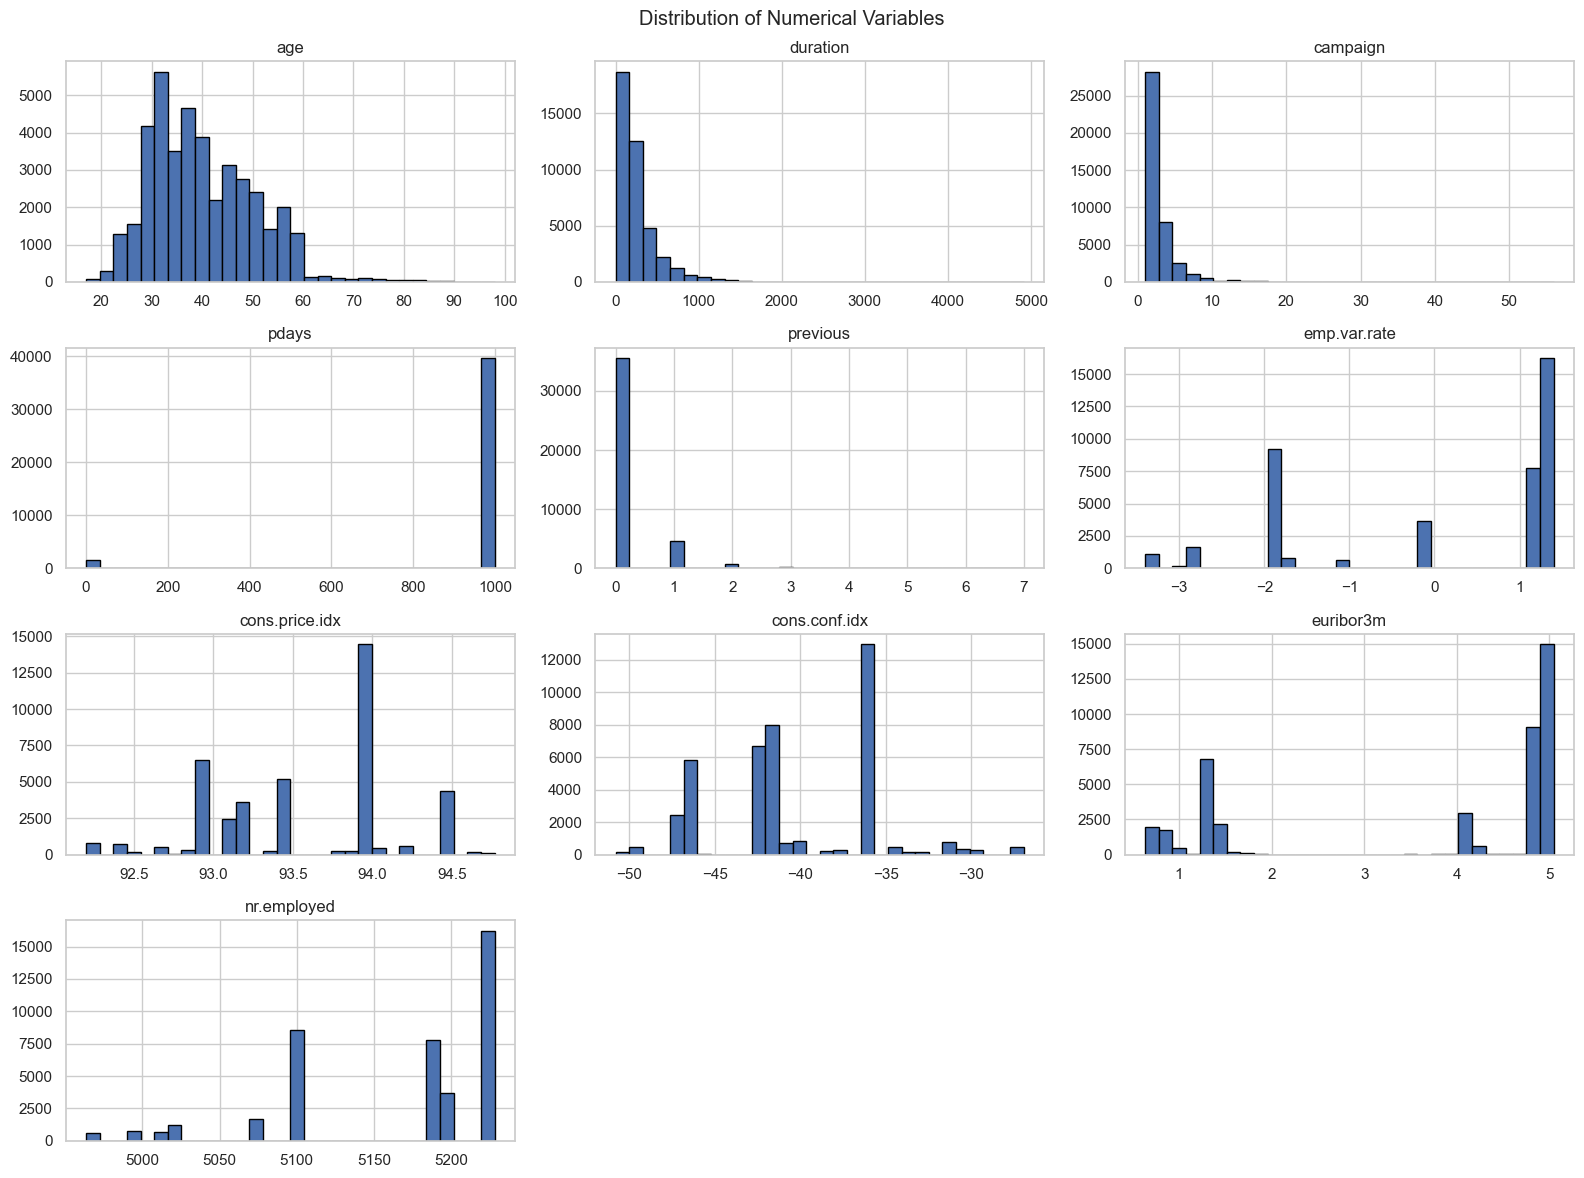


Frequency distribution: job


job
admin.           10419
blue-collar       9253
technician        6739
services          3967
management        2924
retired           1718
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64


Frequency distribution: marital


marital
married     24921
single      11564
divorced     4611
unknown        80
Name: count, dtype: int64


Frequency distribution: education


education
university.degree      12164
high.school             9512
basic.9y                6045
professional.course     5240
basic.4y                4176
basic.6y                2291
unknown                 1730
illiterate                18
Name: count, dtype: int64

... (10 outputs left out)


Frequency distribution: day_of_week


day_of_week
thu    8618
mon    8512
wed    8134
tue    8086
fri    7826
Name: count, dtype: int64


Frequency distribution: poutcome


poutcome
nonexistent    35551
failure         4252
success         1373
Name: count, dtype: int64

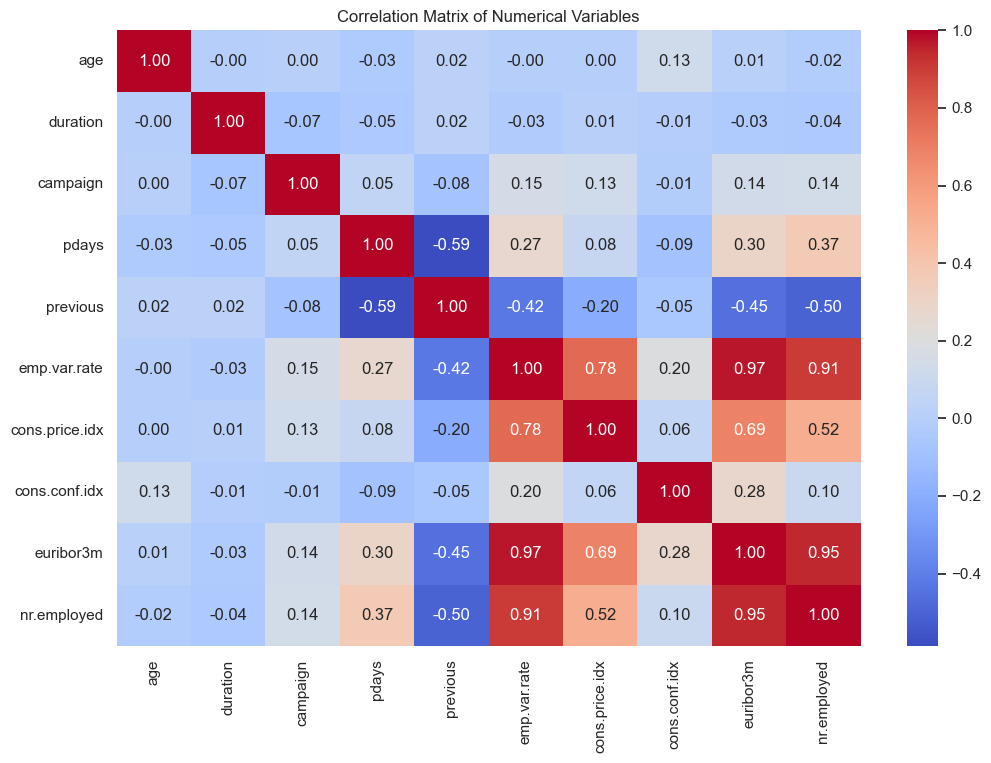

In [34]:
#  EXPLORE THE TARGET VARIABLE
print("Target variable distribution:")
display(df["y"].value_counts())

print("\nTarget percentage:")
display((df["y"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="y")
plt.title("Distribution of Term Deposit Subscription")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")
plt.show()


# 8. EXPLORE NUMERICAL VARIABLES
numeric_columns = df.select_dtypes(include=np.number).columns

display(df[numeric_columns].describe().T)

df[numeric_columns].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Variables")
plt.tight_layout()
plt.show()


#  EXPLORE CATEGORICAL VARIABLES
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    if col == "y":
        continue

    print("\nFrequency distribution:", col)
    display(df[col].value_counts().head(15))


#  CORRELATION ANALYSIS
plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Variables")
plt.show()

### PREPARING DATA FOR CLASSIFICATION

In [35]:

# The duration variable is excluded because it is only known
# after the telephone call. Using it would cause target leakage
# when selecting customers before making a call.

X = df.drop(columns=["y", "duration"])
y = df["y"].map({"no": 0, "yes": 1})

print("Predictor dimensions:", X.shape)
print("Target dimensions:", y.shape)

print("\nTarget distribution:")
display(y.value_counts())


# IDENTIFY NUMERICAL AND CATEGORICAL PREDICTORS
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical predictors:", numeric_features)
print("\nCategorical predictors:", categorical_features)


#  SPLIT THE DATA INTO TRAINING AND TESTING SETS
# A stratified split preserves the proportion of yes/no customers.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining target proportions:")
display(y_train.value_counts(normalize=True))

print("\nTesting target proportions:")
display(y_test.value_counts(normalize=True))


Predictor dimensions: (41176, 19)
Target dimensions: (41176,)

Target distribution:


y
0    36537
1     4639
Name: count, dtype: int64

Numerical predictors: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical predictors: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Training records: 32940
Testing records: 8236

Training target proportions:


y
0    0.887341
1    0.112659
Name: proportion, dtype: float64


Testing target proportions:


y
0    0.887324
1    0.112676
Name: proportion, dtype: float64

In [36]:
#  BUILD THE PREPROCESSING PIPELINE
# Numerical missing values: median imputation.
# Categorical missing values: most frequent imputation.
# Categorical variables: one-hot encoding.
# Numerical variables: standardisation.

try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    # Compatibility with older scikit-learn versions
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)
#  ESTABLISH A MAJORITY-CLASS BASELINE
baseline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

print("MAJORITY-CLASS BASELINE")
print(classification_report(
    y_test,
    baseline_predictions,
    zero_division=0
))

#  DEFINE THE CLASSIFICATION MODELS

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        solver="liblinear",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=250,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Histogram Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.1,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=RANDOM_STATE
    )
}


MAJORITY-CLASS BASELINE
              precision    recall  f1-score   support

           0       0.89      1.00      0.94      7308
           1       0.00      0.00      0.00       928

    accuracy                           0.89      8236
   macro avg       0.44      0.50      0.47      8236
weighted avg       0.79      0.89      0.83      8236



In [40]:
!pip install jinja2

Defaulting to user installation because normal site-packages is not writeable
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)

   ---------------------------------------- 0/2 [MarkupSafe]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\BISHOP LUBEGA\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip



Training: Logistic Regression

Training: Random Forest

Training: Histogram Gradient Boosting

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
1,Random Forest,0.8878,0.5022,0.4957,0.4989,0.7985,0.4685
0,Logistic Regression,0.8303,0.3591,0.6455,0.4615,0.8002,0.4466
2,Histogram Gradient Boosting,0.9008,0.6628,0.2435,0.3562,0.8141,0.4906


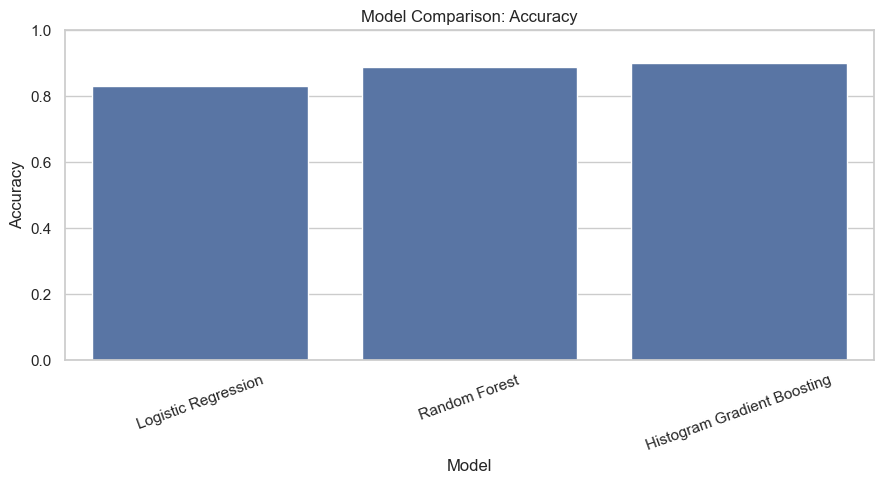

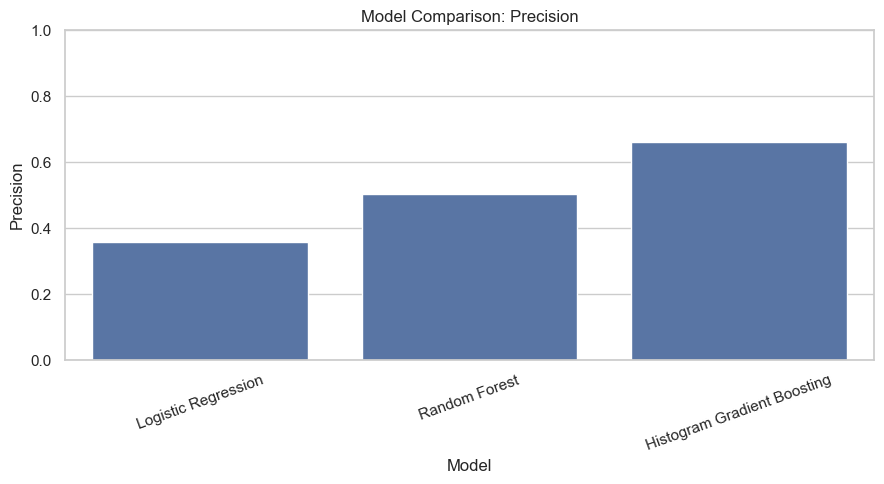

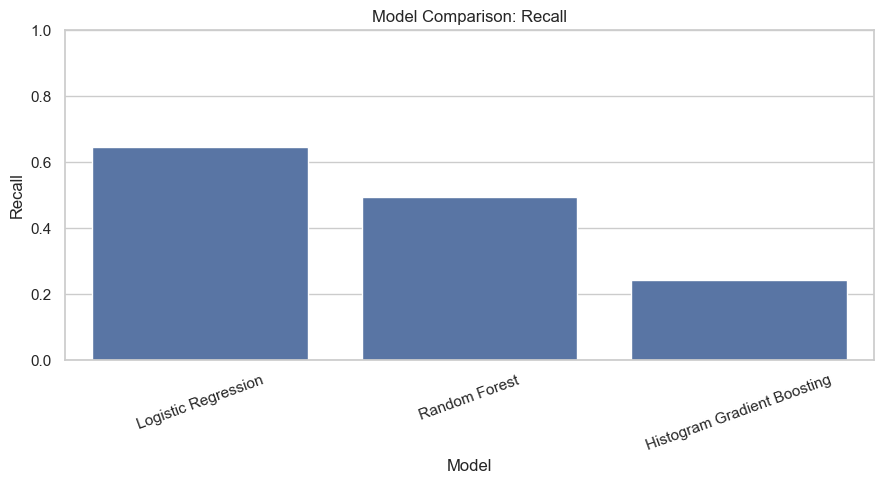

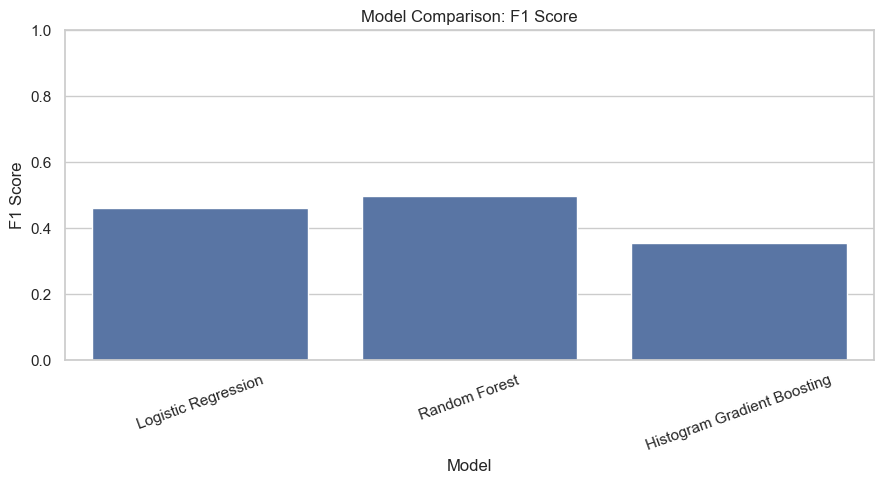

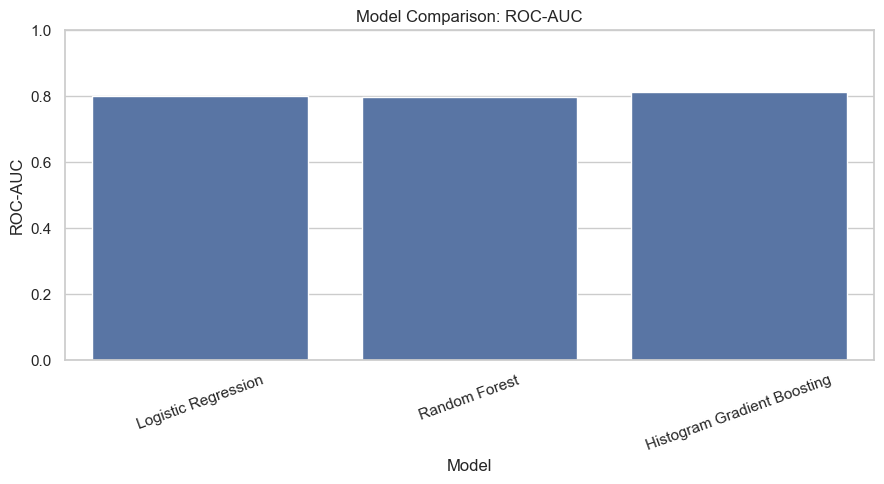

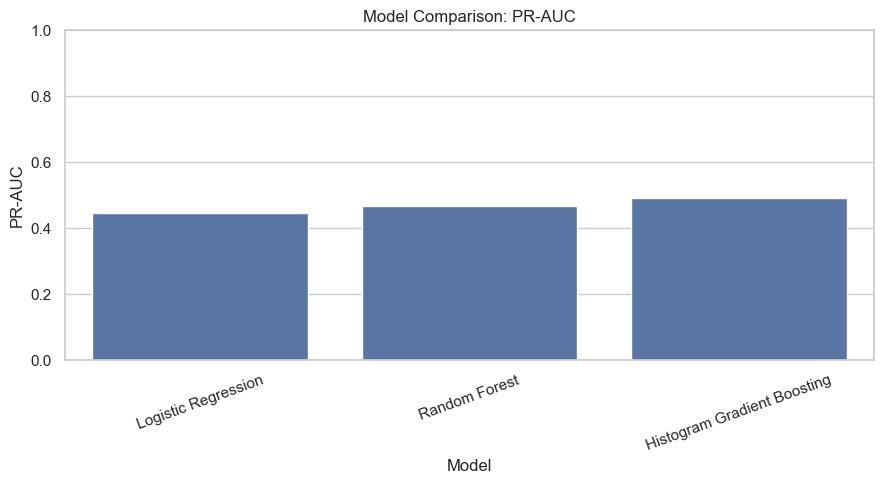

Best model based on F1 Score: Random Forest


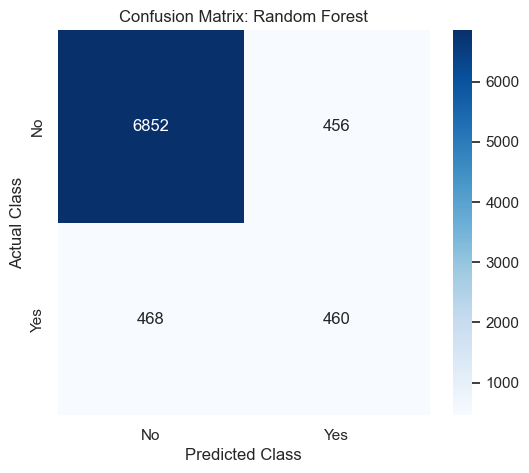

Classification report:
                  precision    recall  f1-score   support

 No subscription       0.94      0.94      0.94      7308
Yes subscription       0.50      0.50      0.50       928

        accuracy                           0.89      8236
       macro avg       0.72      0.72      0.72      8236
    weighted avg       0.89      0.89      0.89      8236



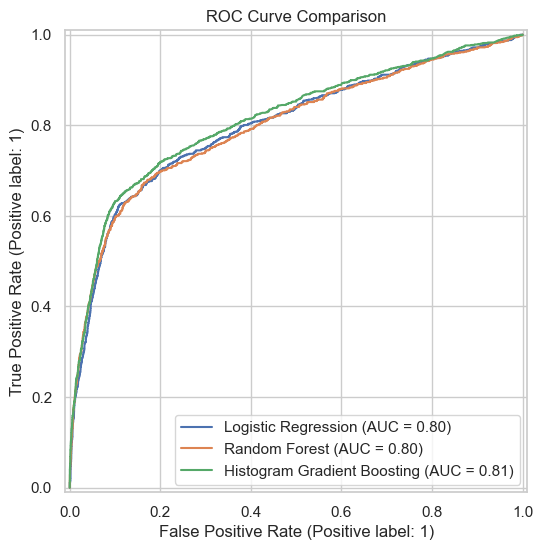

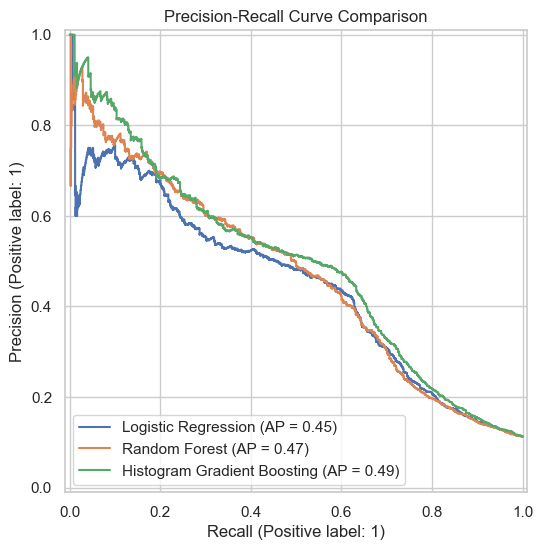

In [41]:
#  TRAIN AND EVALUATE THE MODELS
fitted_models = {}
results = []

for model_name, classifier in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    print("\nTraining:", model_name)

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    fitted_models[model_name] = pipeline

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

print("\nMODEL PERFORMANCE COMPARISON")
display(
    results_df.sort_values("F1 Score", ascending=False)
    .style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)


# 18. VISUALISE MODEL PERFORMANCE
metrics_to_plot = [
    "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC", "PR-AUC"
]

for metric in metrics_to_plot:
    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric
    )

    plt.title(f"Model Comparison: {metric}")
    plt.xticks(rotation=20)
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()


# SELECT THE BEST MODEL USING F1 SCORE
# F1 balances precision and recall for the positive class.

best_model_name = results_df.sort_values(
    "F1 Score", ascending=False
).iloc[0]["Model"]

best_model = fitted_models[best_model_name]

print("Best model based on F1 Score:", best_model_name)


#  CONFUSION MATRIX AND CLASSIFICATION REPORT
best_predictions = best_model.predict(X_test)

cm = confusion_matrix(y_test, best_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title(f"Confusion Matrix: {best_model_name}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

print("Classification report:")
print(classification_report(
    y_test,
    best_predictions,
    target_names=["No subscription", "Yes subscription"],
    zero_division=0
))


#  ROC CURVE COMPARISON
plt.figure(figsize=(8, 6))

for model_name, pipeline in fitted_models.items():

    probabilities = pipeline.predict_proba(X_test)[:, 1]

    RocCurveDisplay.from_predictions(
        y_test,
        probabilities,
        name=model_name,
        ax=plt.gca()
    )

plt.title("ROC Curve Comparison")
plt.show()


#  PRECISION-RECALL CURVE COMPARISON
plt.figure(figsize=(8, 6))

for model_name, pipeline in fitted_models.items():

    probabilities = pipeline.predict_proba(X_test)[:, 1]

    PrecisionRecallDisplay.from_predictions(
        y_test,
        probabilities,
        name=model_name,
        ax=plt.gca()
    )

plt.title("Precision-Recall Curve Comparison")
plt.show()


In [46]:


#  REFIT THE SELECTED MODEL ON ALL TRAINING DATA
# Evaluate on the untouched test set using the validation threshold.

final_model = fitted_models[best_model_name]
final_model.fit(X_train, y_train)

test_probabilities = final_model.predict_proba(X_test)[:, 1]

final_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("FINAL TEST PERFORMANCE")
print(classification_report(
    y_test,
    final_predictions,
    target_names=["No subscription", "Yes subscription"],
    zero_division=0
))

print("Final test ROC-AUC:",
      round(roc_auc_score(y_test, test_probabilities), 4))

print("Final test PR-AUC:",
      round(average_precision_score(y_test, test_probabilities), 4))

print("The end of Question 2")


FINAL TEST PERFORMANCE
                  precision    recall  f1-score   support

 No subscription       0.94      0.92      0.93      7308
Yes subscription       0.47      0.54      0.50       928

        accuracy                           0.88      8236
       macro avg       0.70      0.73      0.72      8236
    weighted avg       0.89      0.88      0.88      8236

Final test ROC-AUC: 0.7985
Final test PR-AUC: 0.4685
The end of Question 2


### Question 3

### Recommended Decision Threshold
For the Bank Marketing classification project, I recommend using the validation threshold that produces the highest F1-score as the initial decision threshold.

This is appropriate because the dataset is imbalanced: approximately 88.7% of customers did not subscribe, while only 11.3% subscribed. The bank therefore needs to identify as many potential subscribers as possible without making excessive unnecessary calls.

Selected validation threshold is: 0.45000000000000007  according to the visual below and 
the recormended threshold is 0.45 as seen from the visual below


,Threshold,Precision,Recall,F1 Score
0,0.10,0.1517,0.8774,0.2587
1,0.15,0.1979,0.7965,0.3171
2,0.20,0.2545,0.7372,0.3784
3,0.25,0.3086,0.6792,0.4244
4,0.30,0.3576,0.6294,0.4561
5,0.35,0.3982,0.5876,0.4747
6,0.40,0.4366,0.5566,0.4893
7,0.45,0.4690,0.5296,0.4975
8,0.50,0.4993,0.4825,0.4907
9,0.55,0.5337,0.4488,0.4876


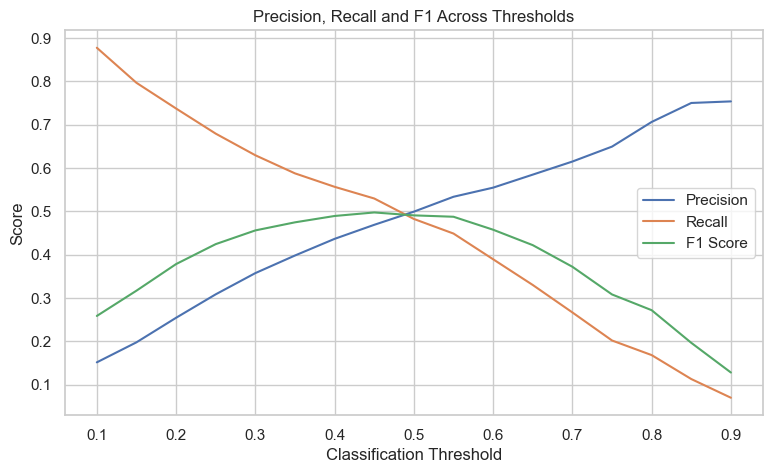

Selected validation threshold: 0.45000000000000007
Recommended decision threshold: 0.45


In [47]:
#  THRESHOLD ANALYSIS USING A VALIDATION SET
# The test set remains untouched for final model evaluation.
# Threshold selection is performed using training data only.

X_subtrain, X_validation, y_subtrain, y_validation = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=RANDOM_STATE
)

validation_model = fitted_models[best_model_name]

# Refit the selected model on the sub-training data
validation_model.fit(X_subtrain, y_subtrain)

validation_probabilities = validation_model.predict_proba(
    X_validation
)[:, 1]

threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.05):

    predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_validation, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_validation, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_validation, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1 Score"],
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 Across Thresholds")
plt.legend()
plt.show()

best_threshold = threshold_df.loc[
    threshold_df["F1 Score"].idxmax(),
    "Threshold"
]

print("Selected validation threshold:", best_threshold)
best_threshold = threshold_df.loc[
    threshold_df["F1 Score"].idxmax(), "Threshold"
]

print("Recommended decision threshold:", round(best_threshold, 2))

### Trade-off between unnecessary calls and missed subscribers

The decision threshold determines when the model classifies a customer as likely to subscribe.
- Lower threshold: More customers are classified as potential subscribers. This increases the likelihood of identifying actual subscribers (higher recall) but also increases unnecessary calls to customers who will not subscribe (false positives).
- Higher threshold: Fewer customers are selected for calls. This reduces unnecessary calls and may improve precision, but increases the risk of missing customers who would have subscribed (false negatives).
Prediction outcome	Meaning	Business implication
True positive	Predicted yes, actually subscribed	Successful customer targeting
False positive	Predicted yes, did not subscribe	Unnecessary marketing call
True negative	Predicted no, did not subscribe	Unnecessary call avoided
False negative	Predicted no, actually subscribed	Potential subscriber missed

From the visual when the threshold decreases, recall generally increases becasue more potential subscribers are selected and when the threshold increases, precision may improve.

